In [9]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt
import gmsh

from Source.Pre_processing.Mesh import Mesh
from Source.core import Model
from Source.Material import material
from Source.Physics.FluidFlow import ff
from Source.enums import StudyType, ProblemType, SolverType, IterativeSolvers, Preconditioners

In [2]:
L, H, XC, YC, D = 2.2, 0.41, 0.2, 0.2, 0.1
U_MAX, MU, RHO = 1.5, 1e-3, 1.0
U_MEAN = 2.0 / 3.0 * U_MAX
T_END, DT = float(os.environ.get("CYLINDER_T_END", 8.0)), 0.01
T_FORCES = 2.0                      # the forces are evaluated over the last T_FORCES seconds (periodic regime)

In [3]:
def channel_mesh(lc_far=0.025, lc_cyl=0.006):

    gmsh.initialize()
    gmsh.option.setNumber("General.Terminal", 0)
    try:
        gmsh.model.add('cilindro')
        occ = gmsh.model.occ
        box = occ.addRectangle(0, 0, 0, L, H)
        disk = occ.addDisk(XC, YC, 0, D / 2, D / 2)
        fluid, _ = occ.cut([(2, box)], [(2, disk)])
        occ.synchronize()

        groups = {'inlet': [], 'outlet': [], 'walls': [], 'cylinder': []}
        for _, tag in gmsh.model.getBoundary(fluid, oriented=False):
            x, y, _ = occ.getCenterOfMass(1, tag)
            if abs(x) < 1e-9:
                groups['inlet'].append(tag)
            elif abs(x - L) < 1e-9:
                groups['outlet'].append(tag)
            elif abs(y) < 1e-9 or abs(y - H) < 1e-9:
                groups['walls'].append(tag)
            else:
                groups['cylinder'].append(tag)
        for name, tags in groups.items():
            gmsh.model.addPhysicalGroup(1, tags, name=name)

        field = gmsh.model.mesh.field
        dist = field.add('Distance')
        field.setNumbers(dist, 'CurvesList', groups['cylinder'])
        thr = field.add('Threshold')
        field.setNumber(thr, 'InField', dist)
        field.setNumber(thr, 'SizeMin', lc_cyl)
        field.setNumber(thr, 'SizeMax', lc_far)
        field.setNumber(thr, 'DistMin', 0.01)
        field.setNumber(thr, 'DistMax', 0.25)
        field.setAsBackgroundMesh(thr)
        gmsh.option.setNumber('Mesh.MeshSizeExtendFromBoundary', 0)

        gmsh.model.mesh.generate(2)
        return Mesh.from_gmsh_model()
    finally:
        gmsh.finalize()

In [ ]:
mesh = channel_mesh()
xy = np.array([node.coor for node in mesh.NL])
cylinder = mesh.boundary_edges('cylinder')


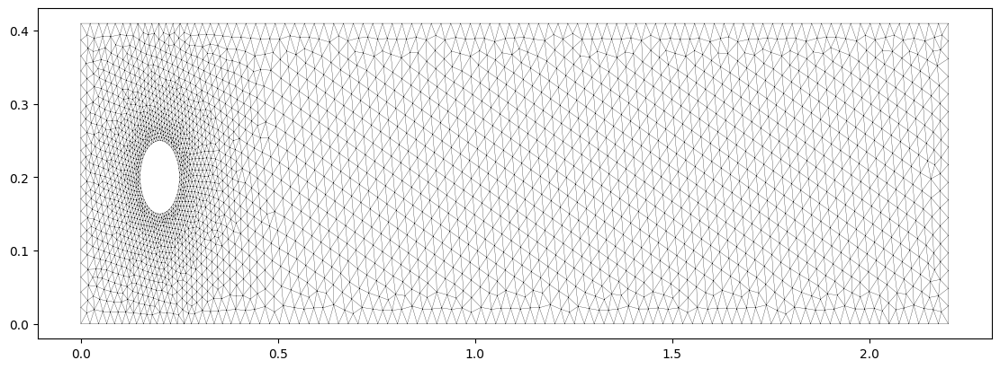

In [5]:
triang = mesh.triangulation()
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
ax.triplot(triang, lw=0.2, color='k')
plt.show()

In [6]:
model = Model(name='cilindro', dim=2, mesh=mesh, mat=material('fluido', miu=MU, rho=RHO), psc=ff)
flow = model.physics
flow.setInertia(True)
flow.addBC_VelocityEdges(mesh.boundary_edges('inlet'), lambda x, y: (4 * U_MAX * y * (H - y) / H ** 2, 0.0))
flow.addBC_NoSlipEdges(mesh.boundary_edges('walls'))
flow.addBC_NoSlipEdges(cylinder)
flow.addBC_OutletEdges(mesh.boundary_edges('outlet'), 0.0, fully_developed=False)
flow.initField('u', 0.0)
print(f"Malla: {mesh.getNoN()} nodos, {mesh.getNoE()} triángulos, {model.layout.ndof} incógnitas; "
      f"Re = {RHO * U_MEAN * D / MU:.0f}")

Malla: 2926 nodos, 5574 triángulos, 8778 incógnitas; Re = 100


In [11]:
model.solverConfiguration(Study=StudyType.transient, Type=ProblemType.nonlinear, Method=SolverType.iterative,
                          Solver=IterativeSolvers.GMRES, prec = Preconditioners.AMG, timeStep=DT, totalTime=T_END, timeScheme='BDF2')
start = time.perf_counter()
model.solve()
elapsed = time.perf_counter() - start
print(f"{len(model.step_iterations)} pasos en {elapsed / 60:.1f} min; Newton por paso: "
      f"{np.mean(model.step_iterations):.1f} de media, {max(model.step_iterations)} como máximo")

2026-11-03 20:39:11 - INFO - ------- Starting simulation -------
2026-11-03 20:39:11 - INFO - Model: cilindro
2026-11-03 20:39:11 - INFO - Dimension: 2D
2026-11-03 20:39:11 - INFO - Nodes: 2926
2026-11-03 20:39:11 - INFO - Elements: 5574
2026-11-03 20:39:11 - INFO - Physics: Laminar flow (Navier-Stokes)
2026-11-03 20:39:11 - INFO - ------- Solver configuration -------
2026-11-03 20:39:11 - INFO - Study: Transient
2026-11-03 20:39:11 - INFO - Type: Nonlinear
2026-11-03 20:39:11 - INFO - Method: Iterative
2026-11-03 20:39:11 - INFO - Solver: Generalized Minimal Residual
2026-11-03 20:39:11 - INFO - Preconditioner: Algebraic multigrid (pyamg)
2026-11-03 20:39:11 - INFO - Time Discretization: 1, scheme: BDF2
2026-11-03 20:39:11 - INFO - Time Step: 0.01
2026-11-03 20:39:11 - INFO - Total Time: 8.0
2026-11-03 20:39:11 - INFO - Theta = 1.0, scheme = BDF2, steps = 800, dt = 0.01
2026-11-03 20:45:02 - INFO - Paso 80/800 (t = 0.8, 10 %): 351.1 s transcurridos, ~3159.6 s restantes
2026-11-03 20:5

800 pasos en 67.6 min; Newton por paso: 10.4 de media, 22 como máximo


In [12]:
times = np.asarray(model.timeVector)
U_hist, P_hist = model.sol['u'], model.sol['p']
layout = model.layout

In [14]:
def state(k):
    return layout.join({'u': U_hist[..., k], 'p': P_hist[:, k]})


steps = np.nonzero(times >= T_END - T_FORCES - 1e-9)[0]
drag, lift = [], []
for k in steps:
    flow.var['u'].updateField(U_hist[..., k])
    flow.var['p'].updateField(P_hist[:, k])
    rate = (1.5 * state(k) - 2.0 * state(k - 1) + 0.5 * state(k - 2)) / DT          # BDF2 derivative
    fx, fy = flow.boundaryForce(cylinder, rate=rate)
    drag.append(2 * fx / (RHO * U_MEAN ** 2 * D))
    lift.append(2 * fy / (RHO * U_MEAN ** 2 * D))
drag, lift, t_forces = np.array(drag), np.array(lift), times[steps]

# Strouhal: period from the zero crossings (upwards) of the lift
up = np.nonzero((lift[:-1] < 0) & (lift[1:] >= 0))[0]
crossings = t_forces[up] - lift[up] * (t_forces[up + 1] - t_forces[up]) / (lift[up + 1] - lift[up])
strouhal = D / (np.mean(np.diff(crossings)) * U_MEAN) if len(crossings) > 1 else np.nan

print(f"C_D,max = {drag.max():.4f}   (referencia 3.22 - 3.24)")
print(f"C_L,max = {lift.max():.4f}   (referencia 0.99 - 1.01)")
print(f"St      = {strouhal:.4f}   (referencia 0.295 - 0.305)")


C_D,max = 3.2307   (referencia 3.22 - 3.24)
C_L,max = 0.9661   (referencia 0.99 - 1.01)
St      = 0.2905   (referencia 0.295 - 0.305)


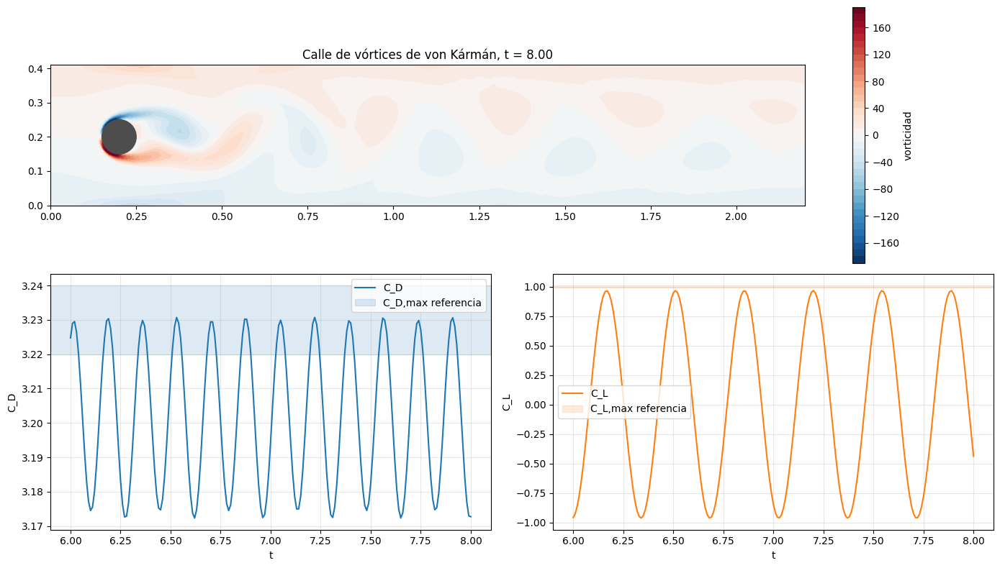

In [15]:
# ----- Gráficos -----
fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 2)
G = model.geometry
omega = G.project(G.gradient(U_hist[..., -1])[..., 1, 0] - G.gradient(U_hist[..., -1])[..., 0, 1])

ax = fig.add_subplot(gs[0, :])
lim = np.percentile(np.abs(omega), 99)
cs = ax.tricontourf(triang, np.clip(omega, -lim, lim), levels=41, cmap='RdBu_r')
fig.colorbar(cs, ax=ax, label='vorticidad')
ax.add_patch(plt.Circle((XC, YC), D / 2, color='0.3'))
ax.set_aspect('equal'); ax.set_title(f'Calle de vórtices de von Kármán, t = {times[-1]:.2f}')

ax = fig.add_subplot(gs[1, 0])
ax.plot(t_forces, drag, label='C_D')
ax.axhspan(3.22, 3.24, color='tab:blue', alpha=0.15, label='C_D,max referencia')
ax.set_xlabel('t'); ax.set_ylabel('C_D'); ax.legend(); ax.grid(True, alpha=0.3)

ax = fig.add_subplot(gs[1, 1])
ax.plot(t_forces, lift, color='tab:orange', label='C_L')
ax.axhspan(0.99, 1.01, color='tab:orange', alpha=0.15, label='C_L,max referencia')
ax.set_xlabel('t'); ax.set_ylabel('C_L'); ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
U_hist

array([[[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00]],

       [[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00]],

       [[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00]],

       ...,

       [[ 0.00000000e+00,  1.08062957e+00,  9.60498601e-01, ...,
          2.18321197e-01,  2.28777060e-01,  2.38263231e-01],
        [ 0.00000000e+00,  5.09250615e-02,  4.58262550e-02, ...,
          8.39720093e-03,  7.19209

In [18]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# ----- Parámetros -----
T_ANIM_START = 0.0      # tiempo inicial de la animación
T_ANIM_END = times[-1]  # tiempo final
DT_ANIM = 0.1           # intervalo entre fotogramas (en segundos de simulación)
FPS = 10                # 0.1 s de simulación por fotograma -> 10 fps = tiempo real

G = model.geometry
t_target = np.arange(T_ANIM_START, T_ANIM_END + 1e-9, DT_ANIM)
frames = np.unique([np.argmin(np.abs(times - t)) for t in t_target])

# ----- Campos por fotograma (se calculan una sola vez) -----
def vorticity(k):
    grad = G.gradient(U_hist[..., k])
    return G.project(grad[..., 1, 0] - grad[..., 0, 1])

def speed(k):
    return np.hypot(U_hist[:, 0, k], U_hist[:, 1, k])

OMEGA = np.array([vorticity(k) for k in frames])     # (nframes, nnodos)
SPEED = np.array([speed(k) for k in frames])

w_lim = np.percentile(np.abs(OMEGA), 99)             # escala de color fija para toda la animación
v_max = SPEED.max()

# ----- Figura -----
fig, (ax_w, ax_v) = plt.subplots(2, 1, figsize=(11, 6.5), constrained_layout=True)

def setup(ax, field, cmap, vmin, vmax, label):
    pc = ax.tripcolor(triang, field, cmap=cmap, vmin=vmin, vmax=vmax, shading='gouraud')
    ax.add_patch(plt.Circle((XC, YC), D / 2, color='0.3', zorder=3))
    ax.set_aspect('equal')
    ax.set_xlim(0, L); ax.set_ylim(0, H)
    fig.colorbar(pc, ax=ax, label=label, pad=0.01)
    return pc

pc_w = setup(ax_w, OMEGA[0], 'RdBu_r', -w_lim, w_lim, 'vorticidad')
pc_v = setup(ax_v, SPEED[0], 'viridis', 0.0, v_max, '|u|')
title = fig.suptitle('')

def update(i):
    pc_w.set_array(OMEGA[i])
    pc_v.set_array(SPEED[i])
    title.set_text(f't = {times[frames[i]]:.2f}')
    return pc_w, pc_v, title

anim = FuncAnimation(fig, update, frames=len(frames), interval=1000 / FPS, blit=False)
plt.close(fig)                       # evita mostrar el fotograma estático duplicado

# Opción A: reproducir dentro del cuaderno
HTML(anim.to_jshtml())

Animation size has reached 21292738 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.
